In [1]:
# coding: utf-8

__author__ = "Gouvenou Pierre, Van Gennip Simon"

# Import necessary libraries

import json
import numpy as np
import matplotlib.pyplot as plt
import datetime
import xarray as xr
import os, glob,sys
import pandas as pd
from configparser import ConfigParser
import getpass
import ftputil
from tqdm import tqdm
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from scipy.stats import pearsonr
import matplotlib


# Read information from the configuration file

config_object = ConfigParser()
config_object.read("config_base.ini")
config_info = config_object['CONFIG_BASE']
MODELS = config_info["MODELS"].split(',')
LON_MIN = int(config_info["lon_min"])
LON_MAX = int(config_info["lon_max"])
LAT_MIN = int(config_info["lat_min"])
LAT_MAX = int(config_info["lat_max"])
DEPTH = int(config_info["depth"])
DATE1 = config_info["DATE_start"]
DATE2 = config_info["DATE_end"]
PROJECT = config_info["PROJECT"]
EXP_NAME = config_info["EXP_NAME"]
USERNAME = config_info["username"]
DIR_WORK = config_info["dir_work"]
DIR_IN = config_info["dir_in"]
REMOTE = bool(config_info["remote"])
COPERNICUS_DRIFTER = bool(config_info["copernicus_drifter"])
DRIFT_TIME = int(config_info["DRIFT_TIME"])


# Print configuration information

print("MODELS : ",MODELS)
print("Region : ",LON_MIN,", ",LON_MAX,", ",LAT_MIN,", ",LAT_MAX)
print("From : ",DATE1," to ",DATE2)

# Add a directory to the Python sys path

sys.path.append("src/")

# Import custom functions from local module

from Drift_Tools import ReturnUVlist, ExtractSurface, match_elements, StringRegion, DispDirAndLength,  SeparationDistance, TrajDistBetweenTimesteps, SepDistanceEachTimestep, LiuScore2, shift360, DriftersInZoneInPeriod, coord2index, DriftersInZoneInPeriod_remote

from Functions import Retrieve_traj_files,Retrieve_drifters_traj,Traj_filter,Report_card_plot

# Create an output directory path

STR_REGION = StringRegion(LON_MIN,LON_MAX,LAT_MIN,LAT_MAX)
DIR_OUT=DIR_WORK+"DRIFT/"+PROJECT+'/'+EXP_NAME+'/ZONE_'+STR_REGION+'/'
print("Dir out : ",DIR_OUT)

# Retrieve the starting date and the ending date

DD1=np.int32(DATE1[:2])
MM1=np.int32(DATE1[2:4])
YYYY1=np.int32(DATE1[4:])
DD2=np.int32(DATE2[:2])
MM2=np.int32(DATE2[2:4])
YYYY2=np.int32(DATE2[4:])
DATE_START = datetime.date(YYYY1, MM1, DD1)
STR_DATE_START= DATE_START.strftime('%Y-%m-%d')
DATE_START_MIN1 = DATE_START-datetime.timedelta(days=1)
DATE_END=datetime.date(YYYY2, MM2, DD2)
STR_DATE_END=DATE_END.strftime('%Y-%m-%d')
DATE_END_PLUS1 = DATE_END+datetime.timedelta(days=1)
DATE_END_PLUS_DRIFT_TIME =  DATE_END+datetime.timedelta(days=DRIFT_TIME+1)
STR_DATE_END_PLUS_DRIFT_TIME=DATE_END_PLUS_DRIFT_TIME.strftime('%Y-%m-%d')
T_DRIFT = (DATE_END_PLUS_DRIFT_TIME -DATE_START).days





traj_lon,traj_lat,traj_time = Retrieve_traj_files(MODELS,DIR_OUT)


fout_driftersZone = 'Drifters_'+STR_REGION+'_'+STR_DATE_START+'_'+STR_DATE_END_PLUS_DRIFT_TIME+'.csv'
dir_drifters = DIR_OUT+'/DRIFTERS/'


outfile2 = dir_drifters+fout_driftersZone

traj_drifter_lon,traj_drifter_lat,traj_drifter_date,traj_drifter_time,traj_drifter_id = Retrieve_drifters_traj(outfile2,T_DRIFT,REMOTE,COPERNICUS_DRIFTER)

# Plot Drifter's trajectories

dir_plot = DIR_OUT+'PLOT/'


if not os.path.exists(dir_plot):
    print('\ncreate folder : ', dir_plot)
    # Create directory where to store results:
    os.makedirs(dir_plot)

fig = plt.figure(figsize = (9,5))
axs=plt.axes(projection=ccrs.PlateCarree())
axs.coastlines()
axs.add_feature(cfeature.LAND)
gl = axs.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False)
gl.xlabels_top = False
gl.ylabels_right = False
fig.suptitle('Trajectory of the SVP drifters',fontsize = 12)

axs.plot(traj_drifter_lon.T,traj_drifter_lat.T,transform=ccrs.PlateCarree())
axs.set_xlim([LON_MIN,LON_MAX])
axs.set_ylim([LAT_MIN,LAT_MAX])
plt.savefig(dir_plot+'Traj_drifters'+STR_DATE_START+'_'+STR_DATE_END+'.png',dpi = 600)

drifter_lon,drifter_lat = Traj_filter(REMOTE,COPERNICUS_DRIFTER, DRIFT_TIME,traj_drifter_lon,traj_drifter_lat, traj_lon,traj_lat)



sep_dist = SeparationDistance(drifter_lon,drifter_lat,traj_lon,traj_lat)
liu_score = np.array([[LiuScore2(drifter_lon[i,j],drifter_lat[i,j],traj_lon[i,j],traj_lat[i,j]).T for j in range(traj_lon.shape[1])] for i in range (traj_lon.shape[0])])
skill_score = 1-liu_score
nans = np.unique(np.where(np.isnan(traj_lon))[2])
if len(nans)>0:
    traj_lon = np.delete(traj_lon,nans,axis = 2)
    traj_lat = np.delete(traj_lat,nans,axis = 2)
    drifter_lon = np.delete(drifter_lon,nans,axis = 2)
    drifter_lat = np.delete(drifter_lat,nans,axis = 2)

corr_lon = np.array([[[pearsonr(drifter_lon[i,j,k],traj_lon[i,j,k])[0] for k in range(traj_lon.shape[2])] for j in range(traj_lon.shape[1])] for i in range(traj_lon.shape[0])])
corr_lat = np.array([[[pearsonr(drifter_lat[i,j,k],traj_lat[i,j,k])[0] for k in range(traj_lat.shape[2])] for j in range(traj_lat.shape[1])] for i in range(traj_lat.shape[0])])



prop_sep_dist = np.count_nonzero(sep_dist[:,:,:,-1]<50 ,axis =(1,2) )/ (sep_dist.shape[1]*sep_dist.shape[2])
prop_skill_score = np.count_nonzero(skill_score[:,:,:,-1]>0 ,axis =(1,2) )/ (skill_score.shape[1]*skill_score.shape[2])
prop_corr_lon = np.count_nonzero(corr_lon>0.7 ,axis =(1,2) )/ (corr_lon.shape[1]*corr_lon.shape[2])
prop_corr_lat = np.count_nonzero(corr_lat>0.7 ,axis =(1,2) )/ (corr_lat.shape[1]*corr_lat.shape[2])

MODELS :  ['cmems_mod_glo_phy-cur_anfc_0.083deg_P1D-m', 'dataset-uv-nrt-daily']
Region :  -19 ,  5 ,  26 ,  56
From :  15012023  to  20012023
username:  pgouvenou
Dir out :  /data/rd_exchange/pgouvenou/DRIFT/project_test/test_coper_dri/ZONE_19W5E-26N56N/


/home/pgouvenou/miniconda3/envs/env_validation_tools/lib/python3.11/site-packages/xarray/coding/times.py:254: RuntimeWarning: invalid value encountered in cast
  flat_num_dates_ns_int = (flat_num_dates * _NS_PER_TIME_DELTA[delta]).astype(
/home/pgouvenou/miniconda3/envs/env_validation_tools/lib/python3.11/site-packages/xarray/coding/times.py:254: RuntimeWarning: invalid value encountered in cast
  flat_num_dates_ns_int = (flat_num_dates * _NS_PER_TIME_DELTA[delta]).astype(
/home/pgouvenou/miniconda3/envs/env_validation_tools/lib/python3.11/site-packages/xarray/coding/times.py:254: RuntimeWarning: invalid value encountered in cast
  flat_num_dates_ns_int = (flat_num_dates * _NS_PER_TIME_DELTA[delta]).astype(
/home/pgouvenou/miniconda3/envs/env_validation_tools/lib/python3.11/site-packages/xarray/coding/times.py:254: RuntimeWarning: invalid value encountered in cast
  flat_num_dates_ns_int = (flat_num_dates * _NS_PER_TIME_DELTA[delta]).astype(
/home/pgouvenou/miniconda3/envs/env_validati

loading  /data/rd_exchange/pgouvenou/DRIFT/project_test/test_coper_dri/ZONE_19W5E-26N56N//DRIFTERS/Drifters_19W5E-26N56N_2023-01-15_2023-01-24.csv
   Unnamed: 0       id        date      time        lat    lon
0         0.0  1301723  2023-01-15  12:00:00  34.175999 -8.559
1         0.0  1301723  2023-01-15  13:00:00  34.174999 -8.564
2         0.0  1301723  2023-01-15  14:00:00  34.174000 -8.568
3         0.0  1301723  2023-01-15  15:00:00  34.173000 -8.572
4         0.0  1301723  2023-01-15  16:00:00  34.172001 -8.575
Unnamed: 0    float64
id              int64
date           object
time           object
lat           float64
lon           float64
dtype: object


/home/pgouvenou/miniconda3/envs/env_validation_tools/lib/python3.11/site-packages/cartopy/mpl/gridliner.py:451: UserWarning: The .xlabels_top attribute is deprecated. Please use .top_labels to toggle visibility instead.
  warnings.warn('The .xlabels_top attribute is deprecated. Please '
/home/pgouvenou/miniconda3/envs/env_validation_tools/lib/python3.11/site-packages/cartopy/mpl/gridliner.py:487: UserWarning: The .ylabels_right attribute is deprecated. Please use .right_labels to toggle visibility instead.
  warnings.warn('The .ylabels_right attribute is deprecated. Please '
/home/pgouvenou/miniconda3/envs/env_validation_tools/lib/python3.11/site-packages/scipy/stats/_stats_py.py:4781: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  warnings.warn(stats.ConstantInputWarning(msg))


In [4]:
matplotlib.use('Agg')
%matplotlib inline

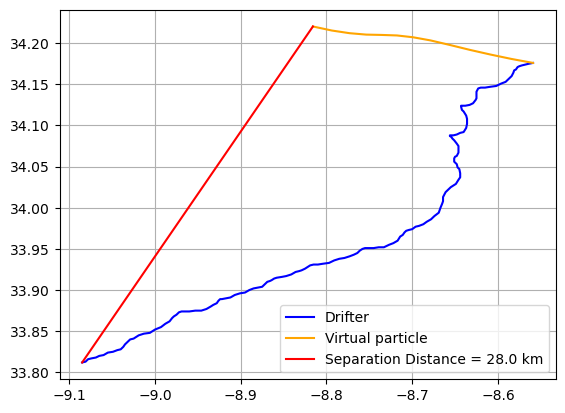

In [5]:
plt.plot(traj_drifter_lon.T[:,0][:-24*2+1],traj_drifter_lat.T[:,0][:-24*2+1],c='b',label = 'Drifter')
plt.plot(traj_lon[0,0,0],traj_lat[0,0,0],c = 'orange',label = 'Virtual particle')
plt.plot([traj_drifter_lon.T[:,0][:-24*2+1][-1],traj_lon[0,0,0][-1]],[traj_drifter_lat.T[:,0][:-24*2+1][-1],
                                                                      traj_lat[0,0,0][-1]],c = 'r',label = 'Separation Distance = '+str(round(sep_dist[0,0,0][-1],1)) +' km')
plt.grid()
plt.legend()
#plt.savefig('/home/pgouvenou/Documents/Figures_outil_validation_lagrangienne/separation_distance_diapo.png',dpi = 400)

(26.0, 56.0)

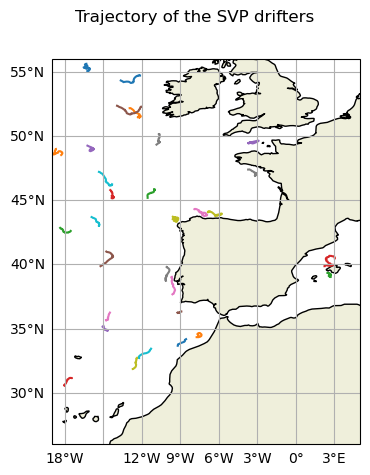

In [7]:
fig = plt.figure(figsize = (9,5))
axs=plt.axes(projection=ccrs.PlateCarree())
axs.coastlines()
axs.add_feature(cfeature.LAND)
gl = axs.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False)
gl.xlabels_top = False
gl.ylabels_right = False
fig.suptitle('Trajectory of the SVP drifters',fontsize = 12)

axs.plot(traj_drifter_lon.T,traj_drifter_lat.T,transform=ccrs.PlateCarree())
axs.set_xlim([LON_MIN,LON_MAX])
axs.set_ylim([LAT_MIN,LAT_MAX])

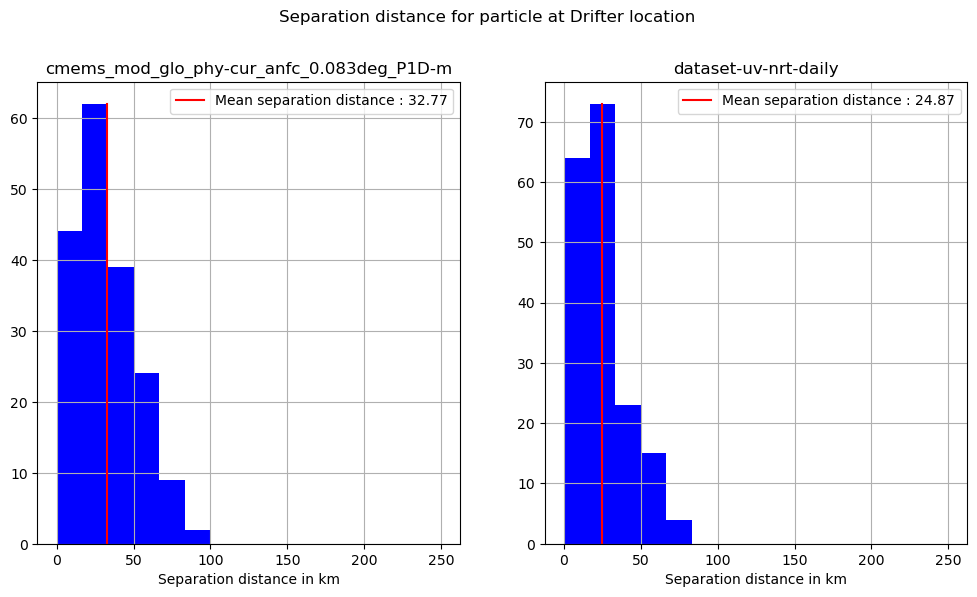

In [9]:
fig,axs = plt.subplots(nrows=1, ncols=len(MODELS),figsize = (6*len(MODELS),6))
fig.suptitle('Separation distance for particle at Drifter location',y = 1,x = 0.5,fontsize = 12)
n_sep = []
x_sep = []
if len(MODELS) == 1:
    n1, x1, _  = axs.hist(sep_dist[0].flatten(),bins =15,range=(0,250),color='b')
    axs.plot(np.nanmean(sep_dist[0,:,:,-1].flatten())*np.ones(2),[0,n1.max()],color= 'r',
                  label = 'Mean separation distance : ' + str(np.round(np.nanmean(sep_dist[0,:,:,-1].flatten()),2)))
    axs.set_title(MODELS[0])
    axs.set_xlabel('Separation distance in km')
    axs.legend()
    axs.grid()
    n_sep.append(n1)
    x_sep.append(x1)
    
else :     
    for i in range(len(MODELS)):
        n1, x1, _  = axs[i].hist(sep_dist[i,:,:,-1].flatten(),bins =15,range=(0,250),color='b')
        axs[i].plot(np.nanmean(sep_dist[i,:,:,-1].flatten())*np.ones(2),[0,n1.max()],color= 'r',
                      label = 'Mean separation distance : ' + str(np.round(np.nanmean(sep_dist[i,:,:,-1].flatten()),2)))
        axs[i].set_title(MODELS[i])
        axs[i].set_xlabel('Separation distance in km')
        axs[i].legend()
        axs[i].grid()

        n_sep.append(n1)
        x_sep.append(x1)
plt.savefig(DIR_OUT+'PLOT/Separation_dis_hist.png',dpi = 400)

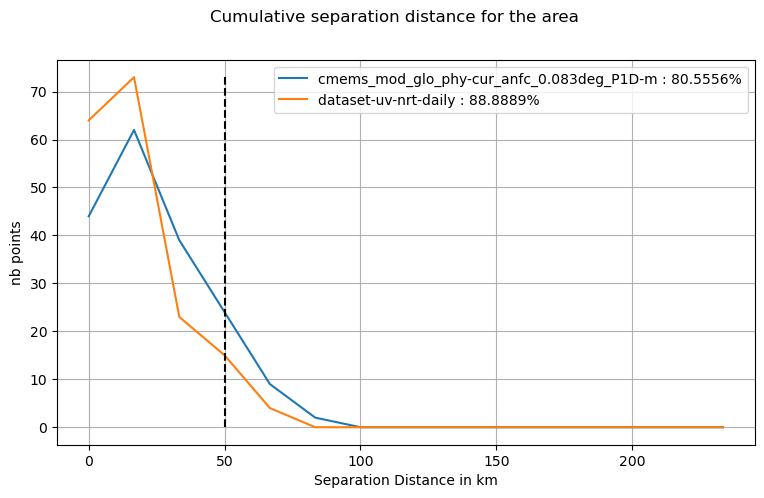

In [10]:
fig,axs = plt.subplots(nrows=1, ncols=1,figsize = (9,5))
fig.suptitle('Cumulative separation distance for the area',fontsize = 12)
for i in range (len(MODELS)):
    axs.plot(x_sep[i][:-1],n_sep[i],label =MODELS[i]+' : '+str(round(prop_sep_dist[i]*100,4)) + '%')


axs.plot([50,50],[0,np.max(n_sep)],'--',c='k')
axs.legend()
axs.set_xlabel('Separation Distance in km')
axs.set_ylabel('nb points')
plt.grid()
plt.savefig(DIR_OUT+'PLOT/cumulative_separation.png',dpi = 400)

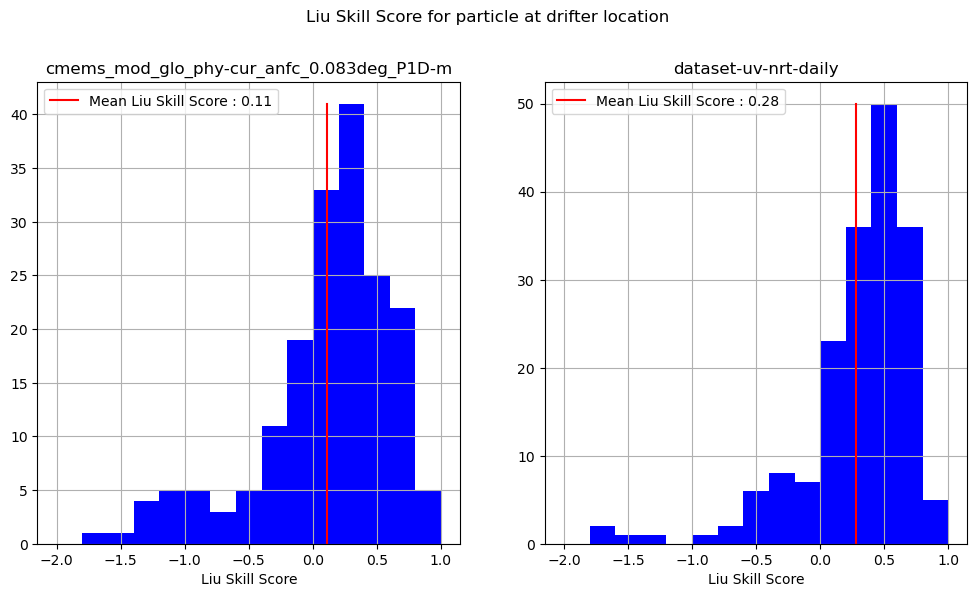

In [11]:
fig,axs = plt.subplots(nrows=1, ncols=len(MODELS),figsize = (6*len(MODELS),6))
fig.suptitle('Liu Skill Score for particle at drifter location',y = 1,x = 0.5,fontsize = 12)
n_liu = []
x_liu = []
if len(MODELS) == 1:
    n1, x1, _  = axs.hist(skill_score[0,:,:,-1].flatten(),bins =15,range=(-2,1),color='b')
    axs.plot(np.nanmean(skill_score[0,:,:,-1].flatten())*np.ones(2),[0,n1.max()],color= 'r',
                  label = 'Mean Liu Skill Score : ' + str(np.round(np.nanmean(skill_score[0,:,:,-1].flatten()),2)))
    axs.set_title(MODELS[0])
    axs.set_xlabel('Liu Skill Score')
    axs.legend()
    axs.grid()
    n_liu.append(n1)
    x_liu.append(x1)
    
else :     
    for i in range(len(MODELS)):
        n1, x1, _  = axs[i].hist(skill_score[i,:,:,-1].flatten(),bins =15,range=(-2,1),color='b')
        axs[i].plot(np.nanmean(skill_score[i,:,:,-1].flatten())*np.ones(2),[0,n1.max()],color= 'r',
                      label = 'Mean Liu Skill Score : ' + str(np.round(np.nanmean(skill_score[i,:,:,-1].flatten()),2)))
        axs[i].set_title(MODELS[i])
        axs[i].set_xlabel('Liu Skill Score')
        axs[i].legend()
        axs[i].grid()

        n_liu.append(n1)
        x_liu.append(x1)
plt.savefig(DIR_OUT+'PLOT/Liu_hist.png',dpi = 400)

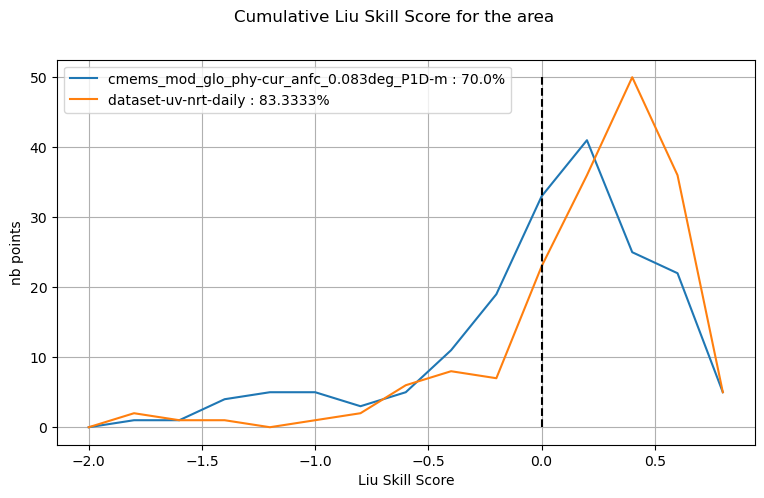

In [12]:
fig,axs = plt.subplots(nrows=1, ncols=1,figsize = (9,5))
fig.suptitle('Cumulative Liu Skill Score for the area',fontsize = 12)
for i in range (len(MODELS)):
    axs.plot(x_liu[i][:-1],n_liu[i],label =MODELS[i]+' : '+str(round(prop_skill_score[i]*100,4)) + '%')


axs.plot([0,0],[0,np.max(n_liu)],'--',c='k')
axs.legend()
axs.set_xlabel('Liu Skill Score')
axs.set_ylabel('nb points')
plt.grid()
plt.savefig(DIR_OUT+'PLOT/Liu_cumulative.png',dpi = 400)

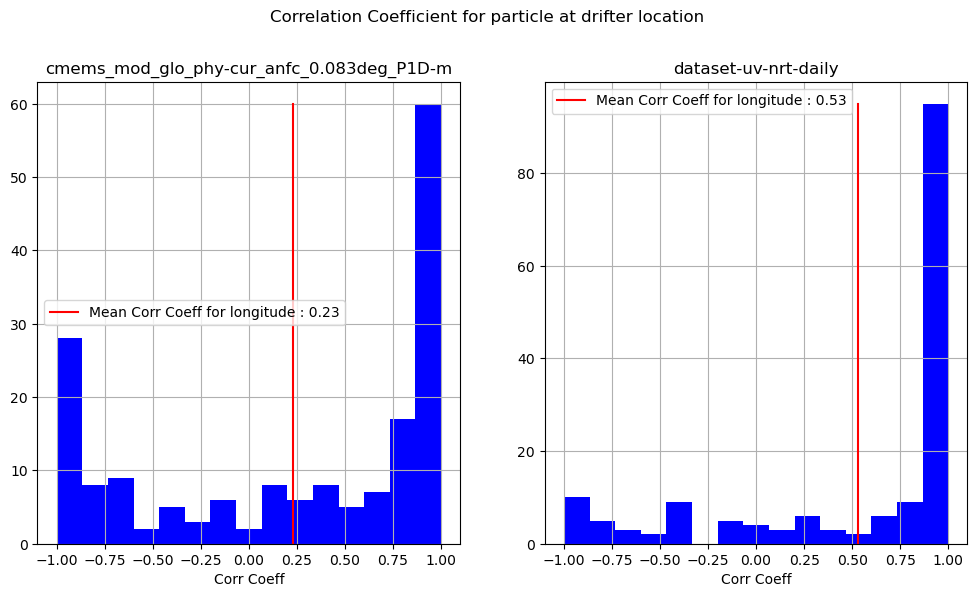

In [13]:
fig,axs = plt.subplots(nrows=1, ncols=len(MODELS),figsize = (6*len(MODELS),6))
fig.suptitle('Correlation Coefficient for particle at drifter location',y = 1,x = 0.5,fontsize = 12)
n_corr_lon = []
x_corr_lon = []
if len(MODELS) == 1:
    n1, x1, _  = axs.hist(corr_lon[0].flatten(),bins =15,range=(-1,1),color='b')
    axs.plot(np.nanmean(corr_lon[0].flatten())*np.ones(2),[0,n1.max()],color= 'r',
                  label = 'Mean Corr Coeff for longitude : ' + str(np.round(np.nanmean(corr_lon[0].flatten()),2)))
    axs.set_title(MODELS[0])
    axs.set_xlabel('Corr Coeff')
    axs.legend()
    axs.grid()
    n_corr_lon.append(n1)
    x_corr_lon.append(x1)
    
else :     
    for i in range(len(MODELS)):
        n1, x1, _  = axs[i].hist(corr_lon[i].flatten(),bins =15,range=(-1,1),color='b')
        axs[i].plot(np.nanmean(corr_lon[i].flatten())*np.ones(2),[0,n1.max()],color= 'r',
                      label = 'Mean Corr Coeff for longitude : ' + str(np.round(np.nanmean(corr_lon[i].flatten()),2)))
        axs[i].set_title(MODELS[i])
        axs[i].set_xlabel('Corr Coeff')
        axs[i].legend()
        axs[i].grid()

        n_corr_lon.append(n1)
        x_corr_lon.append(x1)
plt.savefig(DIR_OUT+'PLOT/Corr_coef_lon_hist.png',dpi = 400)

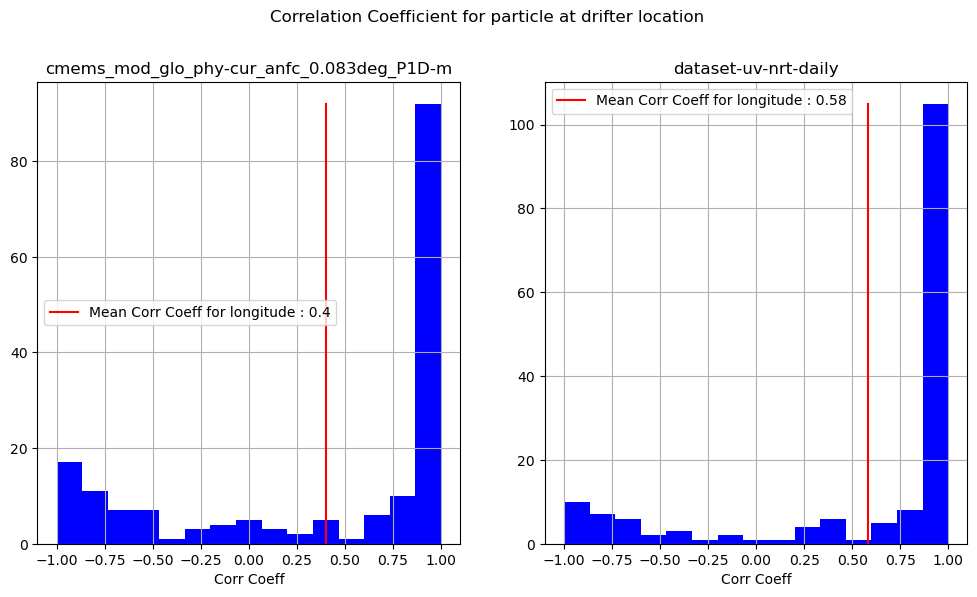

In [14]:
fig,axs = plt.subplots(nrows=1, ncols=len(MODELS),figsize = (6*len(MODELS),6))
fig.suptitle('Correlation Coefficient for particle at drifter location',y = 1,x = 0.5,fontsize = 12)
n_corr_lat = []
x_corr_lat = []
if len(MODELS) == 1:
    n1, x1, _  = axs.hist(corr_lat[0].flatten(),bins =15,range=(-1,1),color='b')
    axs.plot(np.nanmean(corr_lat[0].flatten())*np.ones(2),[0,n1.max()],color= 'r',
                  label = 'Mean Corr Coeff for latitude : ' + str(np.round(np.nanmean(corr_lat[0].flatten()),2)))
    axs.set_title(MODELS[0])
    axs.set_xlabel('Corr Coeff')
    axs.legend()
    axs.grid()
    n_corr_lat.append(n1)
    x_corr_lat.append(x1)
    
else :     
    for i in range(len(MODELS)):
        n1, x1, _  = axs[i].hist(corr_lat[i].flatten(),bins =15,range=(-1,1),color='b')
        axs[i].plot(np.nanmean(corr_lat[i].flatten())*np.ones(2),[0,n1.max()],color= 'r',
                      label = 'Mean Corr Coeff for longitude : ' + str(np.round(np.nanmean(corr_lat[i].flatten()),2)))
        axs[i].set_title(MODELS[i])
        axs[i].set_xlabel('Corr Coeff')
        axs[i].legend()
        axs[i].grid()

        n_corr_lat.append(n1)
        x_corr_lat.append(x1)
plt.savefig(DIR_OUT+'PLOT/Corr_coef_lat_hist.png',dpi = 400)

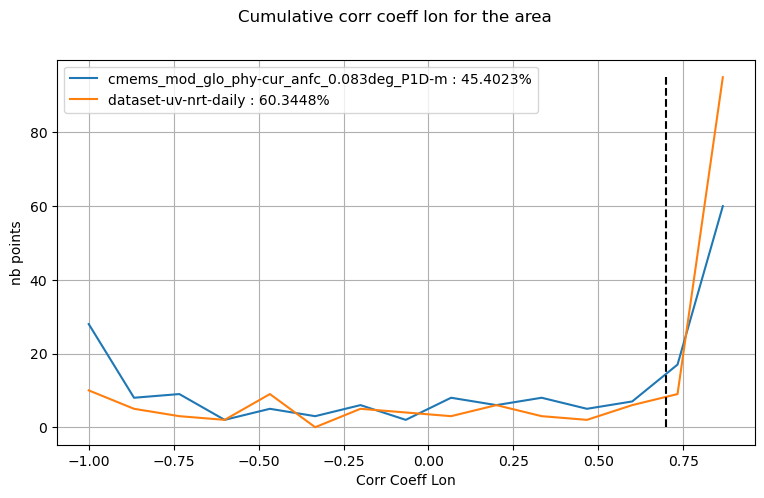

In [15]:
fig,axs = plt.subplots(nrows=1, ncols=1,figsize = (9,5))
fig.suptitle('Cumulative corr coeff lon for the area',fontsize = 12)
for i in range (len(MODELS)):
    axs.plot(x_corr_lon[i][:-1],n_corr_lon[i],label =MODELS[i]+' : '+str(round(prop_corr_lon[i]*100,4)) + '%')


axs.plot([0.7,0.7],[0,np.max(n_corr_lon)],'--',c='k')
axs.legend()
axs.set_xlabel('Corr Coeff Lon')
axs.set_ylabel('nb points')
plt.grid()
plt.savefig(DIR_OUT+'PLOT/Corr_coef_lon_cumulative.png',dpi = 400)

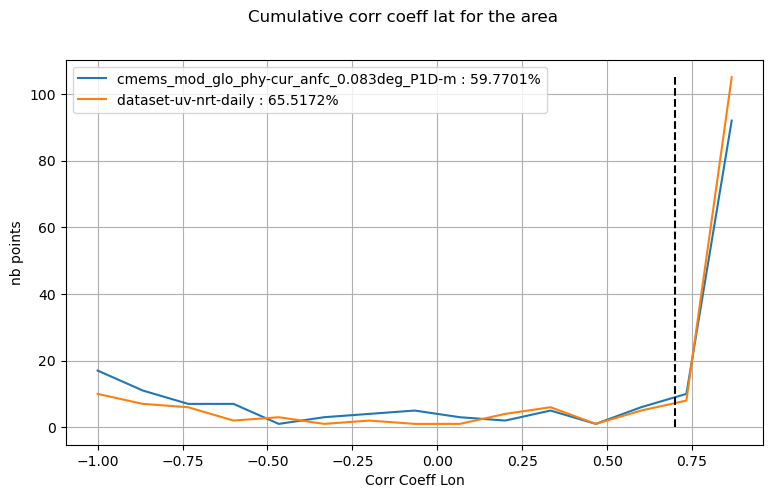

In [16]:
fig,axs = plt.subplots(nrows=1, ncols=1,figsize = (9,5))
fig.suptitle('Cumulative corr coeff lat for the area',fontsize = 12)
for i in range (len(MODELS)):
    axs.plot(x_corr_lat[i][:-1],n_corr_lat[i],label =MODELS[i]+' : '+str(round(prop_corr_lat[i]*100,4)) + '%')


axs.plot([0.7,0.7],[0,np.max(n_corr_lat)],'--',c='k')
axs.legend()
axs.set_xlabel('Corr Coeff Lon')
axs.set_ylabel('nb points')
plt.grid()
plt.savefig(DIR_OUT+'PLOT/Corr_coef_lat_cumulative.png',dpi = 400)